# 01 — Original BlackRock data, EDA and imputation

We forecast official NYSE closing-auction **shares for a stock and trading date**. This notebook establishes the source coverage and eligible labels, examines the auction distribution, and demonstrates how missing predictors are handled using earlier data.

Run the notebooks in numerical order using the project's Python environment. Outputs below were executed against the local BlackRock Parquet files. Each notebook also runs independently from within this repository. Tables and figures are embedded in the notebook. Raw files are read directly and intermediate calculations use temporary storage.

The supplied datasets already contain extracted daily trades and checkpoint aggregates. Individual source trades are outside this dataset, so checks here validate the supplied aggregates and their keys.

| Notebook | Research question | Review point |
| --- | --- | --- |
| 01 | What data are reliable, and how do we handle missingness? | |
| 02 | Which target is suitable for modelling? | |
| 03 | How do raw covariates become useful daily features? | Checkpoint 1 |
| 04 | Which ridge specification and global or segmented architecture works best? | Checkpoint 2 |
| 05 | How did LightGBM tuning produce the daily champion? | Checkpoint 3 |
| 06 | How do tuned CatBoost and XGBoost compare with LightGBM? | Checkpoint 4 |
| 07 | What did market regimes, HMM features, neural networks and blends add? | Checkpoint 4 extension |
| 08 | What did splines, tail mixtures, Tweedie and rebalance features add? | Checkpoint 5 |
| 09 | Which daily forecast should we carry forward? | |
| 10 | How much do intraday updates improve the daily forecast? | Checkpoint 6 |
| 11 | Can several checkpoints, Kalman filters or dynamic regression improve updating? | After Checkpoint 6 |

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))

Matplotlib is building the font cache; this may take a moment.


,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


## Dataset inventory

In [2]:
inventory = sql(f"\nWITH crsp AS (\n  SELECT count(*) AS rows, count(DISTINCT date) AS dates,\n         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date\n  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)\n), auction AS (\n  SELECT count(*) AS rows, count(DISTINCT date) AS dates,\n         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date\n  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)\n), trades AS (\n  SELECT count(*) AS rows, count(DISTINCT date) AS dates,\n         count(DISTINCT permno) AS permnos, min(date) AS min_date, max(date) AS max_date\n  FROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)\n), market AS (\n  SELECT count(*) AS rows, count(DISTINCT date) AS dates,\n         NULL::BIGINT AS permnos, min(date) AS min_date, max(date) AS max_date\n  FROM read_parquet('{str(DATA / 'market/market_daily.parquet')}')\n), sector AS (\n  SELECT count(*) AS rows, count(DISTINCT date) AS dates,\n         NULL::BIGINT AS permnos, min(date) AS min_date, max(date) AS max_date\n  FROM read_parquet('{str(DATA / 'sector/sector_daily.parquet')}')\n)\nSELECT 'CRSP daily' AS dataset, * FROM crsp\nUNION ALL SELECT 'Auction daily', * FROM auction\nUNION ALL SELECT 'Trade checkpoints', * FROM trades\nUNION ALL SELECT 'Market daily', * FROM market\nUNION ALL SELECT 'Sector daily', * FROM sector\n")
display(inventory)

,dataset,rows,dates,permnos,min_date,max_date
0,CRSP daily,4927078,3772,2414,2011-01-03,2025-12-31
1,Auction daily,3594398,2766,2149,2015-01-02,2025-12-31
2,Trade checkpoints,17971990,2766,2149,2015-01-02,2025-12-31
3,Market daily,3772,3772,<NA>,2011-01-03,2025-12-31
4,Sector daily,45264,3772,<NA>,2011-01-03,2025-12-31


## Annual target coverage

,year,stock_days,auction_rows,observed_targets,missing_targets,target_coverage,trading_days,securities
0,2015,341909,341903,337566,4343,0.9873,252,1426
1,2016,329950,329950,325638,4312,0.9869,252,1386
2,2017,321370,321370,318040,3330,0.9896,251,1348
3,2018,317656,317656,313807,3849,0.9879,251,1329
4,2019,316550,316550,308724,7826,0.9753,252,1316
5,2020,312434,312434,303168,9266,0.9703,253,1320
6,2021,336769,336769,321564,15205,0.9549,252,1477
7,2022,353277,353277,328634,24643,0.9302,251,1469
8,2023,331648,331648,318679,12969,0.9609,250,1397
9,2024,321631,321631,316212,5419,0.9832,252,1333


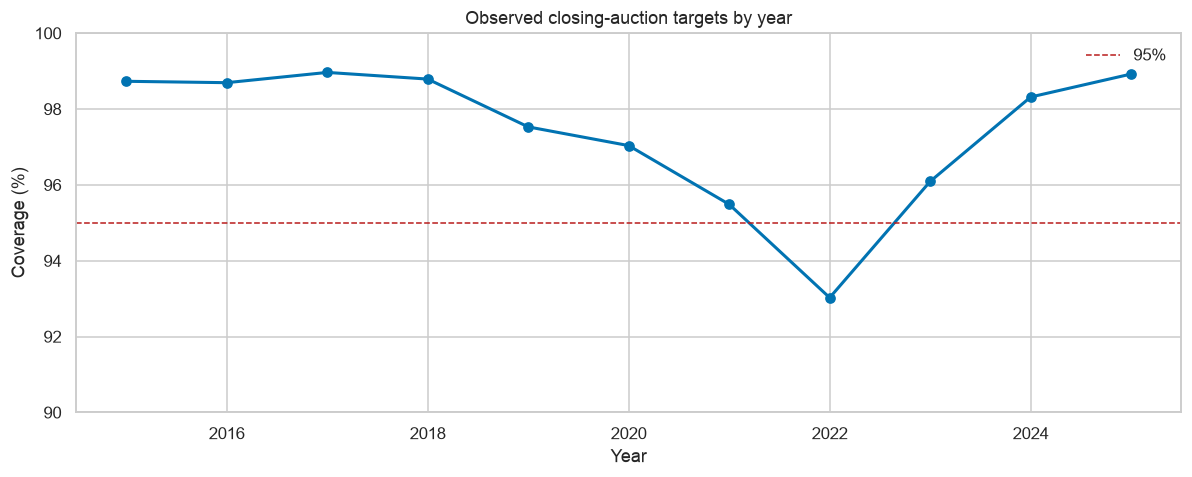

In [3]:
annual = sql(f"\nWITH c AS (\n  SELECT date, permno\n  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)\n  WHERE date >= DATE '2015-01-01'\n), a AS (\n  SELECT date, permno, auction_volume, auction_price, target_found\n  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)\n)\nSELECT year(c.date) AS year,\n       count(*) AS stock_days,\n       count(a.permno) AS auction_rows,\n       count(a.auction_volume) AS observed_targets,\n       count(*) - count(a.auction_volume) AS missing_targets,\n       count(a.auction_volume)::DOUBLE / count(*) AS target_coverage,\n       count(DISTINCT c.date) AS trading_days,\n       count(DISTINCT c.permno) AS securities\nFROM c LEFT JOIN a USING (date, permno)\nGROUP BY 1 ORDER BY 1\n")
display(annual)
fig, ax = plt.subplots()
ax.plot(annual['year'], 100 * annual['target_coverage'], marker='o', linewidth=2)
ax.axhline(95, color='#b91c1c', linestyle='--', linewidth=1, label='95%')
ax.set(title='Observed closing-auction targets by year', ylabel='Coverage (%)', xlabel='Year', ylim=(90, 100))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Daily coverage and source anomalies

,date,stocks,observed,coverage,exclude_from_model,reason
1159,2019-08-12,1261,484,0.3838,True,Abnormally incomplete NYSE condition-6 auction...
1834,2022-04-14,1418,1295,0.9133,False,NaN
1849,2022-05-06,1417,1296,0.9146,False,NaN
1858,2022-05-19,1417,1298,0.9160,False,NaN
1868,2022-06-03,1417,1298,0.9160,False,NaN
1843,2022-04-28,1416,1298,0.9167,False,NaN
1850,2022-05-09,1417,1299,0.9167,False,NaN
1820,2022-03-25,1416,1299,0.9174,False,NaN
1866,2022-06-01,1417,1300,0.9174,False,NaN
1841,2022-04-26,1416,1300,0.9181,False,NaN


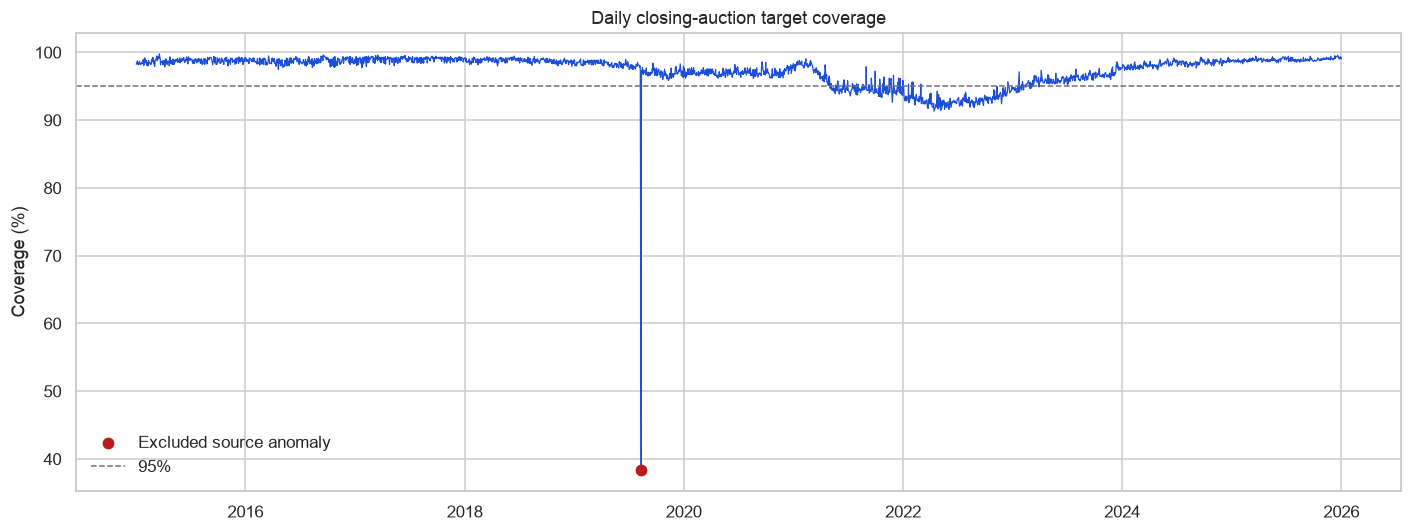

In [4]:
daily = sql(f"\nWITH c AS (\n  SELECT date, permno\n  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)\n  WHERE date >= DATE '2015-01-01'\n), a AS (\n  SELECT date, permno, auction_volume\n  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)\n), an AS (\n  SELECT date, exclude_from_model, reason\n  FROM read_parquet('{ANOMALIES}')\n)\nSELECT c.date, count(*) AS stocks, count(a.auction_volume) AS observed,\n       count(a.auction_volume)::DOUBLE / count(*) AS coverage,\n       coalesce(bool_or(an.exclude_from_model), false) AS exclude_from_model,\n       any_value(an.reason) AS reason\nFROM c LEFT JOIN a USING (date, permno)\nLEFT JOIN an USING (date)\nGROUP BY c.date ORDER BY c.date\n")
display(daily.nsmallest(12, 'coverage'))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily['date'], 100 * daily['coverage'], color='#1d4ed8', linewidth=0.8)
flagged = daily[daily['exclude_from_model']]
ax.scatter(flagged['date'], 100 * flagged['coverage'], color='#b91c1c', s=45, zorder=4, label='Excluded source anomaly')
ax.axhline(95, color='#6b7280', linestyle='--', linewidth=1, label='95%')
ax.set(title='Daily closing-auction target coverage', ylabel='Coverage (%)', xlabel='')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Integrity checks

In [5]:
checks = sql(f"\nWITH a AS (\n  SELECT * FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)\n), c AS (\n  SELECT * FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)\n), t AS (\n  SELECT * FROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)\n)\nSELECT 'auction duplicate date-permno groups' AS check_name,\n       (SELECT count(*) FROM (SELECT date, permno FROM a GROUP BY 1,2 HAVING count(*) > 1)) AS issue_count\nUNION ALL SELECT 'CRSP duplicate date-permno groups',\n       (SELECT count(*) FROM (SELECT date, permno FROM c GROUP BY 1,2 HAVING count(*) > 1))\nUNION ALL SELECT 'trade duplicate date-permno-checkpoint groups',\n       (SELECT count(*) FROM (SELECT date, permno, checkpoint FROM t GROUP BY 1,2,3 HAVING count(*) > 1))\nUNION ALL SELECT 'negative auction volumes', (SELECT count(*) FROM a WHERE auction_volume < 0)\nUNION ALL SELECT 'nonpositive observed auction prices', (SELECT count(*) FROM a WHERE auction_volume IS NOT NULL AND auction_price <= 0)\nUNION ALL SELECT 'auction share above 100%', (SELECT count(*) FROM a WHERE auction_share_daily_volume > 1)\nUNION ALL SELECT 'target flag/value disagreements',\n       (SELECT count(*) FROM a WHERE coalesce(target_found, false) <> (auction_volume IS NOT NULL))\n")
display(checks)

,check_name,issue_count
0,auction duplicate date-permno groups,0
1,CRSP duplicate date-permno groups,0
2,trade duplicate date-permno-checkpoint groups,0
3,negative auction volumes,0
4,nonpositive observed auction prices,0
5,auction share above 100%,0
6,target flag/value disagreements,0


## Missing targets by market-cap decile

,size_decile,stock_days,observed_targets,target_coverage
0,1,360734,310083,0.8596
1,2,360450,331436,0.9195
2,3,360141,353754,0.9823
3,4,359873,355981,0.9892
4,5,359593,357871,0.9952
5,6,359262,358157,0.9969
6,7,359008,357899,0.9969
7,8,358744,358555,0.9995
8,9,358431,358348,0.9998
9,10,358168,357801,0.9990


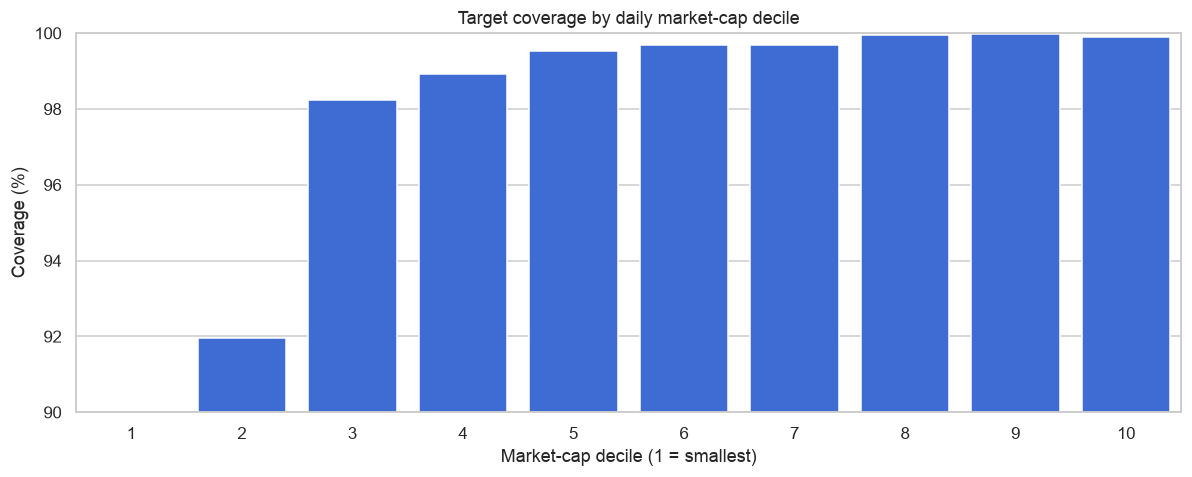

In [6]:
size_coverage = sql(f"\nWITH c AS (\n  SELECT date, permno, market_cap_usd,\n         ntile(10) OVER (PARTITION BY date ORDER BY market_cap_usd) AS size_decile\n  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)\n  WHERE date >= DATE '2015-01-01'\n), a AS (\n  SELECT date, permno, auction_volume\n  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)\n)\nSELECT size_decile, count(*) AS stock_days, count(a.auction_volume) AS observed_targets,\n       count(a.auction_volume)::DOUBLE / count(*) AS target_coverage\nFROM c LEFT JOIN a USING (date, permno)\nGROUP BY 1 ORDER BY 1\n")
display(size_coverage)
fig, ax = plt.subplots()
sns.barplot(data=size_coverage, x='size_decile', y=size_coverage['target_coverage'] * 100, color='#2563eb', ax=ax)
ax.set(title='Target coverage by daily market-cap decile', xlabel='Market-cap decile (1 = smallest)', ylabel='Coverage (%)', ylim=(90, 100))
fig.tight_layout()
plt.show()

## Intraday checkpoint coverage

,checkpoint,rows,data_found_rate,after_close_rows,missing_cum_volume,missing_vwap
0,10:30,3594398,0.9967,0,11990,37422
1,12:00,3594398,0.9967,0,11990,22615
2,14:00,3594398,0.9885,29540,41432,44999
3,15:00,3594398,0.9885,29540,41432,42592
4,15:30,3594398,0.9885,29540,41432,41432


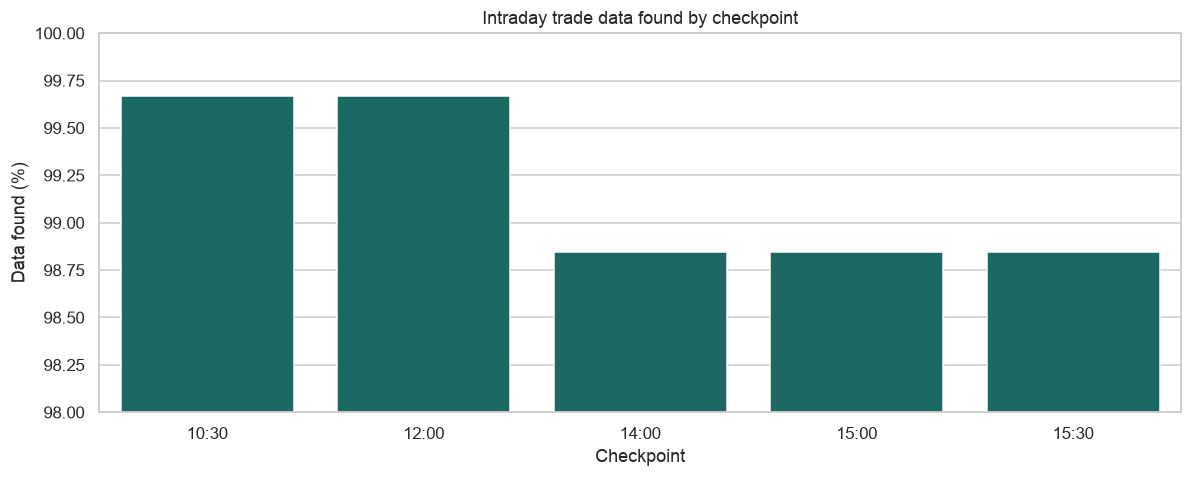

In [7]:
checkpoint = sql(f"\nSELECT checkpoint, count(*) AS rows,\n       avg(checkpoint_data_found::INTEGER) AS data_found_rate,\n       count(*) FILTER (WHERE checkpoint_after_market_close) AS after_close_rows,\n       count(*) FILTER (WHERE cum_volume IS NULL) AS missing_cum_volume,\n       count(*) FILTER (WHERE vwap IS NULL) AS missing_vwap\nFROM read_parquet('{TRADE}', union_by_name=true, hive_partitioning=true)\nGROUP BY 1 ORDER BY strptime(checkpoint, '%H:%M')\n")
display(checkpoint)
fig, ax = plt.subplots()
sns.barplot(data=checkpoint, x='checkpoint', y=checkpoint['data_found_rate'] * 100, color='#0f766e', ax=ax)
ax.set(title='Intraday trade data found by checkpoint', xlabel='Checkpoint', ylabel='Data found (%)', ylim=(98, 100))
fig.tight_layout()
plt.show()

## Auction schema drift

In [8]:
files = sorted((DATA / 'stock_daily/auction_daily').glob('year=*/*.parquet'))
schemas = {}
for file in files:
    year = int(file.parent.name.split('=')[1])
    schemas[year] = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{file}')").fetchall()]
all_columns = sorted(set().union(*map(set, schemas.values())))
schema_matrix = pd.DataFrame({year: [col in columns for col in all_columns] for year, columns in schemas.items()}, index=all_columns)
schema_summary = pd.DataFrame({'year': sorted(schemas), 'column_count': [len(schemas[y]) for y in sorted(schemas)], 'schema_family': ['TAQ-oriented' if len(schemas[y]) < 40 else 'CRSP-enriched' for y in sorted(schemas)]})
display(schema_summary)
display(schema_matrix.loc[schema_matrix.nunique(axis=1) > 1].astype(int))

,year,column_count,schema_family
0,2015,34,TAQ-oriented
1,2016,32,TAQ-oriented
2,2017,32,TAQ-oriented
3,2018,32,TAQ-oriented
4,2019,34,TAQ-oriented
5,2020,58,CRSP-enriched
6,2021,58,CRSP-enriched
7,2022,58,CRSP-enriched
8,2023,58,CRSP-enriched
9,2024,32,TAQ-oriented


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ask,0,0,0,0,0,1,1,1,1,0,1
auction_close_abs_diff,0,0,0,0,0,1,1,1,1,0,1
auction_close_diff_bps,0,0,0,0,0,1,1,1,1,0,1
auction_gt_positive_crsp_volume,0,0,0,0,0,1,1,1,1,0,1
auction_price_raw,1,1,1,1,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
tr_seqnum,1,1,1,1,1,0,0,0,0,1,0
trading_status,0,0,0,0,0,1,1,1,1,0,1
tradingsymbol,1,1,1,1,1,0,0,0,0,1,0
us_incorporated,0,0,0,0,0,1,1,1,1,0,1


**Reading the quality results.** CRSP supplies the stock-day spine, including dates without a matched auction label. PERMNO is the join key and tickers are descriptive. Schema drift is handled with union-by-name and explicit auction columns. A missing target remains missing. The supplied source-anomaly table marks August 12, 2019 for label exclusion. Coverage by size shows whether the observed sample favors more liquid stocks.

Early closes have valid daily auction labels. A 15:30 checkpoint after an early close is unavailable for a forecast at that time. Its treatment belongs in the intraday notebook.

In [9]:
anomalies = sql(f"SELECT * FROM read_parquet('{ANOMALIES}')")
display(anomalies)
assert checks.issue_count.eq(0).all(), "A raw-data integrity check failed"

,date,auction_source_anomaly,exclude_from_model,reason
0,2019-08-12,True,True,Abnormally incomplete NYSE condition-6 auction...


## What auction volume looks like

The following EDA uses observed, eligible auction labels. Volume levels, calendar effects and size differences motivate the target normalisation and feature work in the next two notebooks. Histograms show a capped raw-volume axis for readability. Tail statistics retain the observations.

In [10]:
con.execute(f"""
CREATE OR REPLACE TEMP VIEW eligible_targets AS
WITH c AS (
  SELECT *,
         avg(daily_volume) OVER (
           PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING
         ) AS avg20_daily_volume
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)

), a AS (
  SELECT date, permno, auction_volume, auction_price, auction_share_daily_volume, target_found
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), e AS (
  SELECT * FROM read_parquet('{EVENTS}')
), an AS (
  SELECT date, exclude_from_model FROM read_parquet('{ANOMALIES}')
)
SELECT c.date, c.permno, c.ticker, c.market_cap_usd, c.daily_volume,
       c.return_total, c.avg20_daily_volume,
       a.auction_volume, a.auction_price, a.auction_share_daily_volume,
       ln(1 + a.auction_volume) AS log1p_auction_volume,
       a.auction_volume / nullif(c.avg20_daily_volume, 0) AS auction_to_adv20,
       e.day_of_week, e.is_monday, e.is_friday,
       e.is_last_trading_day_month, e.is_last_trading_day_quarter,
       e.monthly_options_expiry, e.quarterly_options_expiry,
       year(c.date) AS year, month(c.date) AS month
FROM c JOIN a USING (date, permno)
LEFT JOIN e USING (date)
LEFT JOIN an USING (date)
WHERE c.date >= DATE '2015-01-01' AND a.target_found AND a.auction_volume IS NOT NULL
  AND a.auction_volume >= 0
  AND NOT coalesce(an.exclude_from_model, false)
""")

panel_summary = sql("""
SELECT count(*) AS eligible_rows, count(DISTINCT date) AS trading_days,
       count(DISTINCT permno) AS securities, min(date) AS first_date, max(date) AS last_date
FROM eligible_targets
""")
display(panel_summary)

,eligible_rows,trading_days,securities,first_date,last_date
0,3499401,2765,2149,2015-01-02,2025-12-31


## Distribution summary

In [11]:
distribution = sql('\nSELECT count(*) AS n,\n       min(auction_volume) AS min,\n       quantile_cont(auction_volume, 0.01) AS p01,\n       quantile_cont(auction_volume, 0.10) AS p10,\n       quantile_cont(auction_volume, 0.25) AS p25,\n       quantile_cont(auction_volume, 0.50) AS median,\n       quantile_cont(auction_volume, 0.75) AS p75,\n       quantile_cont(auction_volume, 0.90) AS p90,\n       quantile_cont(auction_volume, 0.99) AS p99,\n       max(auction_volume) AS max,\n       avg(auction_volume) AS mean,\n       stddev_samp(auction_volume) AS std_dev,\n       skewness(auction_volume) AS skewness\nFROM eligible_targets\n')
display(distribution.T.rename(columns={0: 'value'}))

,value
n,"3,499,401.0000"
min,1.0000
p01,203.0000
p10,"5,324.0000"
p25,"18,110.0000"
median,"55,226.0000"
p75,"163,418.0000"
p90,"420,623.0000"
p99,"2,075,293.0000"
max,"205,378,788.0000"


## Raw and transformed distributions

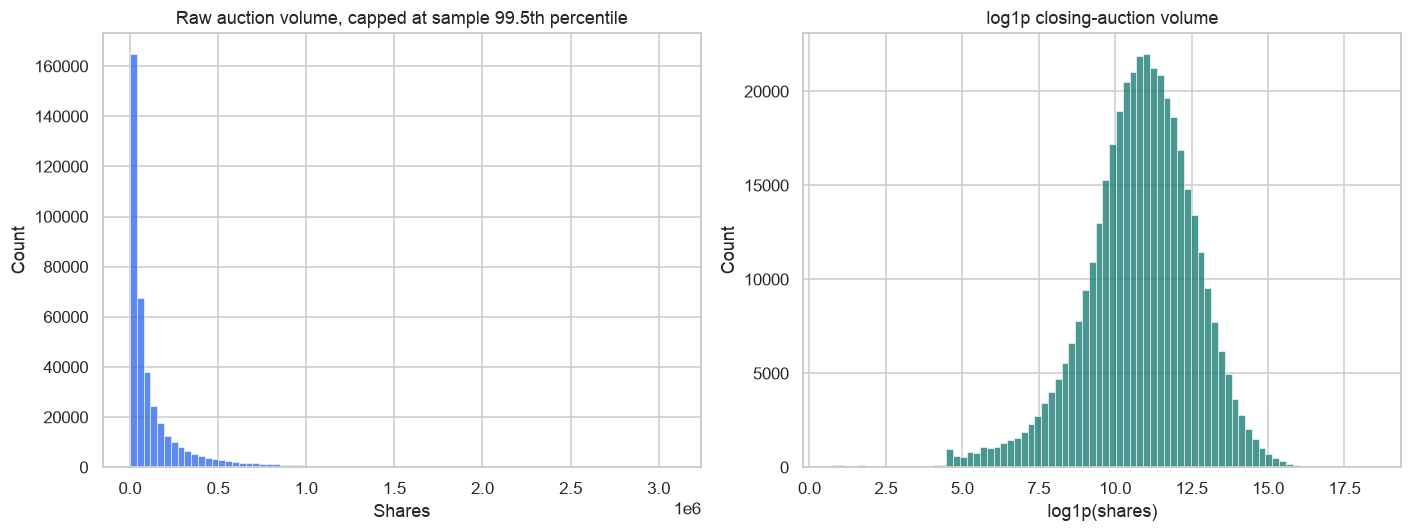

In [12]:
sample = sql('\nSELECT auction_volume, log1p_auction_volume, auction_to_adv20, auction_share_daily_volume\nFROM eligible_targets USING SAMPLE 400000 ROWS (reservoir, 20261011)\n')
raw_cap = sample['auction_volume'].quantile(0.995)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(sample.loc[sample['auction_volume'] <= raw_cap, 'auction_volume'], bins=80, ax=axes[0], color='#2563eb')
axes[0].set(title='Raw auction volume, capped at sample 99.5th percentile', xlabel='Shares')
sns.histplot(sample['log1p_auction_volume'], bins=80, ax=axes[1], color='#0f766e')
axes[1].set(title='log1p closing-auction volume', xlabel='log1p(shares)')
fig.tight_layout()
plt.show()

## Target distribution by year

,year,observations,mean_volume,median_volume,p90_volume,p99_volume,mean_log_volume,median_auction_to_adv20,median_auction_share
0,2015,337566,"111,053.8170","26,179.5000","232,805.0000","1,369,495.4500",10.1624,0.0422,0.0482
1,2016,325638,"123,945.7867","33,463.0000","262,917.9000","1,443,888.9700",10.3357,0.0477,0.0551
2,2017,318040,"132,269.2566","36,875.0000","292,493.9000","1,462,775.4400",10.4284,0.0558,0.0647
3,2018,313807,"171,288.6502","46,948.0000","383,642.2000","1,889,484.3400",10.6858,0.0669,0.0764
4,2019,308240,"181,318.1073","52,923.0000","399,851.0000","1,986,533.1400",10.7951,0.0753,0.0889
5,2020,303168,"214,347.2377","60,827.5000","463,833.1000","2,456,068.1800",10.9531,0.0785,0.0904
6,2021,321564,"180,607.5084","52,176.5000","389,545.0000","2,036,366.8400",10.7288,0.0814,0.0950
7,2022,328634,"194,610.6215","62,564.5000","420,067.1000","2,111,738.7600",10.8807,0.0848,0.0976
8,2023,318679,"220,300.6592","74,877.0000","478,180.0000","2,237,211.5200",11.0787,0.1012,0.1173
9,2024,316212,"259,285.5504","93,278.5000","568,754.9000","2,541,194.0600",11.3036,0.1189,0.1378


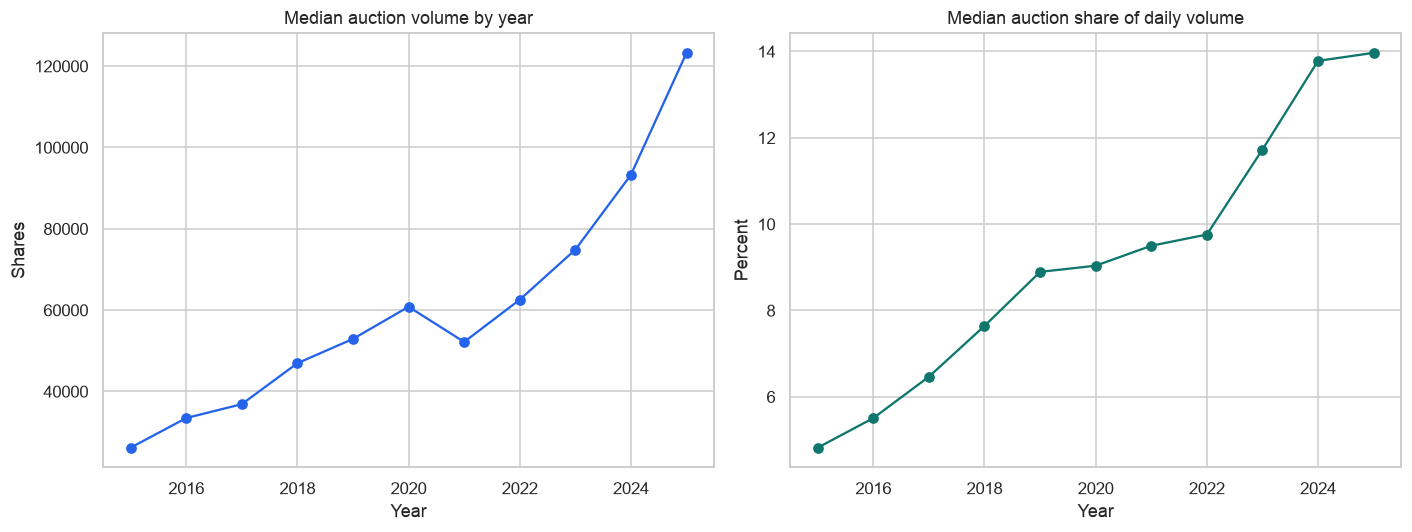

In [13]:
by_year = sql('\nSELECT year, count(*) AS observations,\n       avg(auction_volume) AS mean_volume,\n       median(auction_volume) AS median_volume,\n       quantile_cont(auction_volume, 0.90) AS p90_volume,\n       quantile_cont(auction_volume, 0.99) AS p99_volume,\n       avg(log1p_auction_volume) AS mean_log_volume,\n       median(auction_to_adv20) AS median_auction_to_adv20,\n       median(auction_share_daily_volume) AS median_auction_share\nFROM eligible_targets GROUP BY 1 ORDER BY 1\n')
display(by_year)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(by_year['year'], by_year['median_volume'], marker='o', color='#2563eb')
axes[0].set(title='Median auction volume by year', xlabel='Year', ylabel='Shares')
axes[1].plot(by_year['year'], 100 * by_year['median_auction_share'], marker='o', color='#0f766e')
axes[1].set(title='Median auction share of daily volume', xlabel='Year', ylabel='Percent')
fig.tight_layout()
plt.show()

## Market-wide time series

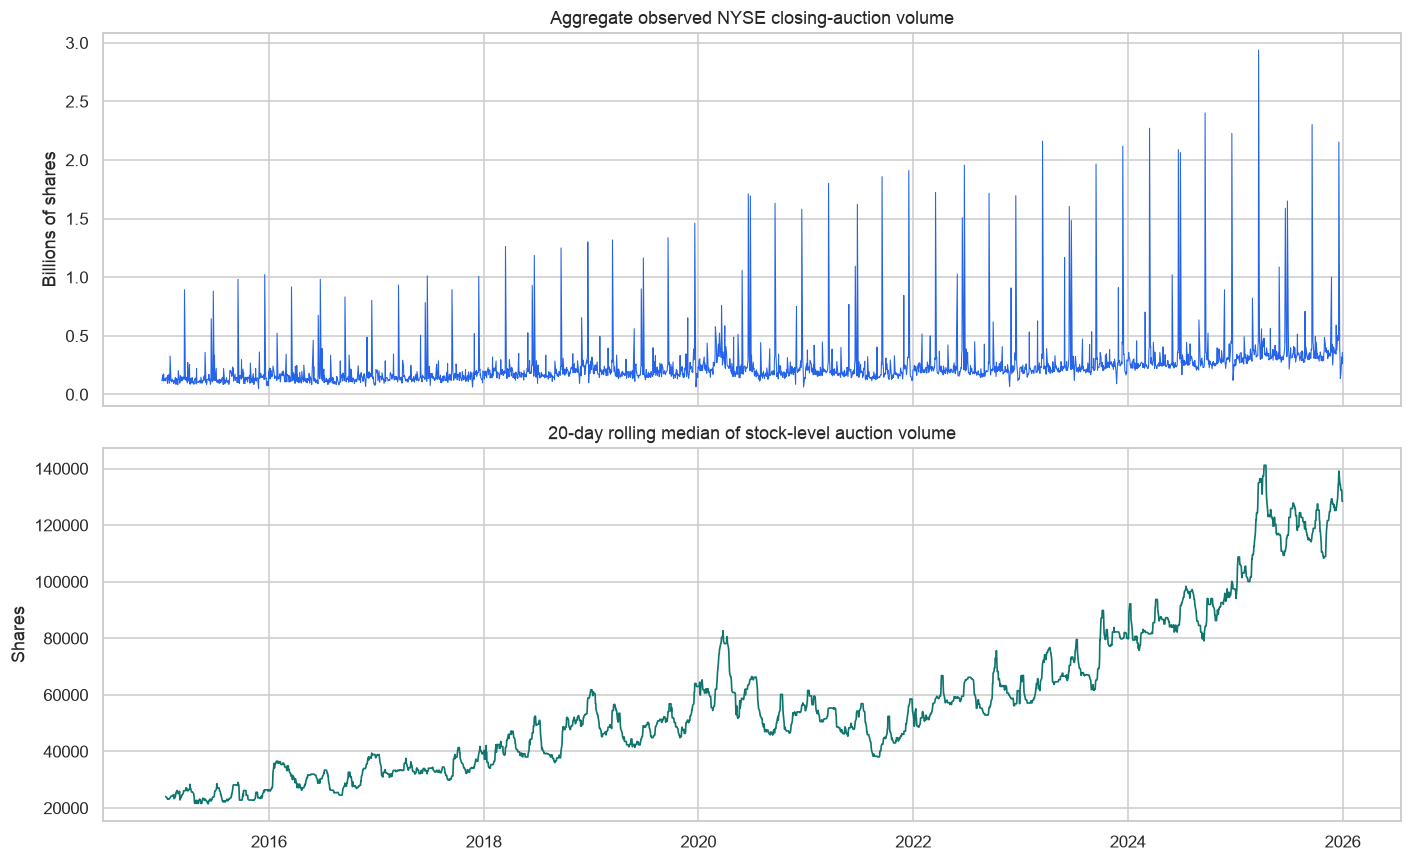

In [14]:
daily_target = sql('\nSELECT date, count(*) AS observed_stocks,\n       sum(auction_volume) AS total_auction_volume,\n       median(auction_volume) AS median_stock_auction_volume,\n       median(auction_share_daily_volume) AS median_auction_share,\n       avg(log1p_auction_volume) AS mean_log_volume\nFROM eligible_targets GROUP BY 1 ORDER BY 1\n')
daily_target['rolling_20d_median'] = daily_target['median_stock_auction_volume'].rolling(20, min_periods=10).median()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(daily_target['date'], daily_target['total_auction_volume'] / 1000000000.0, linewidth=0.7, color='#2563eb')
axes[0].set(title='Aggregate observed NYSE closing-auction volume', ylabel='Billions of shares')
axes[1].plot(daily_target['date'], daily_target['rolling_20d_median'], linewidth=1.1, color='#0f766e')
axes[1].set(title='20-day rolling median of stock-level auction volume', ylabel='Shares', xlabel='')
fig.tight_layout()
plt.show()

## Calendar effects

,effect,category,observations,median_volume,mean_log_volume,median_auction_share
0,Day of week,Friday,702860,"63,697.5000",10.9771,0.1007
1,Day of week,Monday,653074,"53,867.5000",10.7733,0.0887
2,Day of week,Thursday,704809,"52,344.0000",10.7388,0.0845
3,Day of week,Tuesday,721115,"53,584.0000",10.7646,0.0864
4,Day of week,Wednesday,717543,"53,651.0000",10.7616,0.0862
5,Last trading day of month,false,3331673,"53,637.0000",10.7744,0.0870
6,Last trading day of month,true,167728,"97,770.0000",11.3737,0.1447
7,Last trading day of quarter,false,3443528,"54,642.0000",10.7935,0.0883
8,Last trading day of quarter,true,55873,"101,309.0000",11.3938,0.1555
9,Monthly options expiry,false,3331842,"53,817.0000",10.7702,0.0877


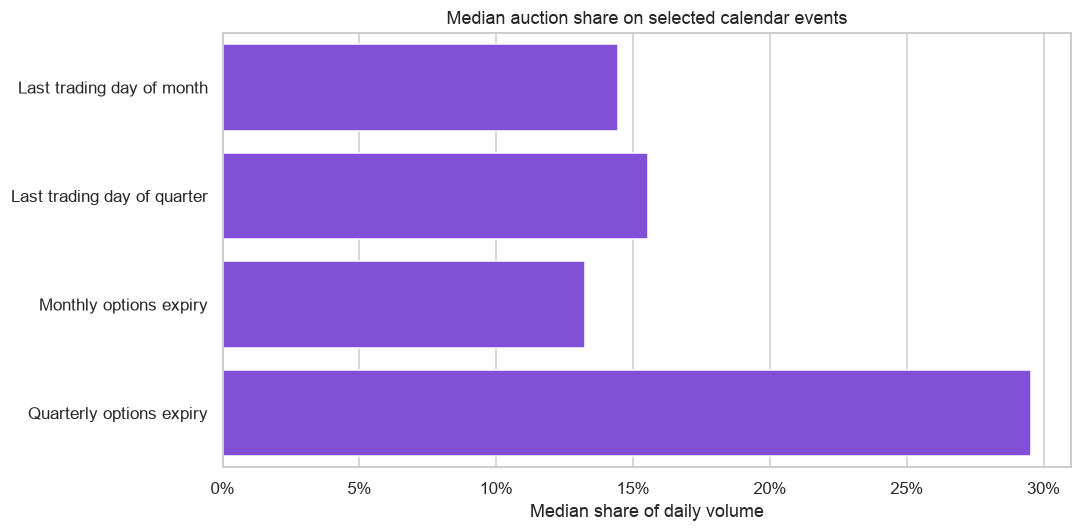

In [15]:
calendar_effects = sql("\nSELECT effect, category, observations, median_volume, mean_log_volume, median_auction_share\nFROM (\n  SELECT 'Day of week' AS effect,\n         CASE day_of_week WHEN 0 THEN 'Monday' WHEN 1 THEN 'Tuesday' WHEN 2 THEN 'Wednesday'\n              WHEN 3 THEN 'Thursday' WHEN 4 THEN 'Friday' ELSE cast(day_of_week AS VARCHAR) END AS category,\n         count(*) AS observations, median(auction_volume) AS median_volume,\n         avg(log1p_auction_volume) AS mean_log_volume,\n         median(auction_share_daily_volume) AS median_auction_share\n  FROM eligible_targets GROUP BY day_of_week\n  UNION ALL\n  SELECT 'Last trading day of month', cast(is_last_trading_day_month AS VARCHAR), count(*),\n         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)\n  FROM eligible_targets GROUP BY is_last_trading_day_month\n  UNION ALL\n  SELECT 'Last trading day of quarter', cast(is_last_trading_day_quarter AS VARCHAR), count(*),\n         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)\n  FROM eligible_targets GROUP BY is_last_trading_day_quarter\n  UNION ALL\n  SELECT 'Monthly options expiry', cast(monthly_options_expiry AS VARCHAR), count(*),\n         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)\n  FROM eligible_targets GROUP BY monthly_options_expiry\n  UNION ALL\n  SELECT 'Quarterly options expiry', cast(quarterly_options_expiry AS VARCHAR), count(*),\n         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)\n  FROM eligible_targets GROUP BY quarterly_options_expiry\n)\nORDER BY effect, category\n")
display(calendar_effects)
binary_effects = calendar_effects[(calendar_effects['effect'] != 'Day of week') & (calendar_effects['category'] == 'true')].copy()
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=binary_effects, y='effect', x='median_auction_share', color='#7c3aed', ax=ax)
ax.xaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
ax.set(title='Median auction share on selected calendar events', xlabel='Median share of daily volume', ylabel='')
fig.tight_layout()
plt.show()

## Cross-sectional size relationship

,size_decile,observations,median_market_cap,median_auction_volume,mean_log_volume,median_auction_to_adv20,median_auction_share
0,1,351166,"166,454,400.0000","4,350.0000",8.2787,0.0313,0.0398
1,2,350902,"477,851,570.0000","16,209.0000",9.6695,0.0648,0.0774
2,3,350642,"957,495,910.0000","28,182.0000",10.2514,0.0765,0.0895
3,4,350356,"1,615,595,135.0000","38,654.5000",10.5653,0.0800,0.0931
4,5,350084,"2,565,287,010.0000","48,603.0000",10.8198,0.0830,0.0958
5,6,349819,"3,894,564,490.0000","55,653.0000",10.9867,0.0802,0.0921
6,7,349545,"6,051,378,510.0000","68,514.0000",11.1835,0.0777,0.0884
7,8,349250,"10,548,037,350.0000","102,317.5000",11.5320,0.0853,0.0967
8,9,348968,"21,719,364,675.0000","170,940.0000",12.0297,0.0925,0.1037
9,10,348669,"69,259,481,150.0000","354,044.0000",12.7399,0.0955,0.1054


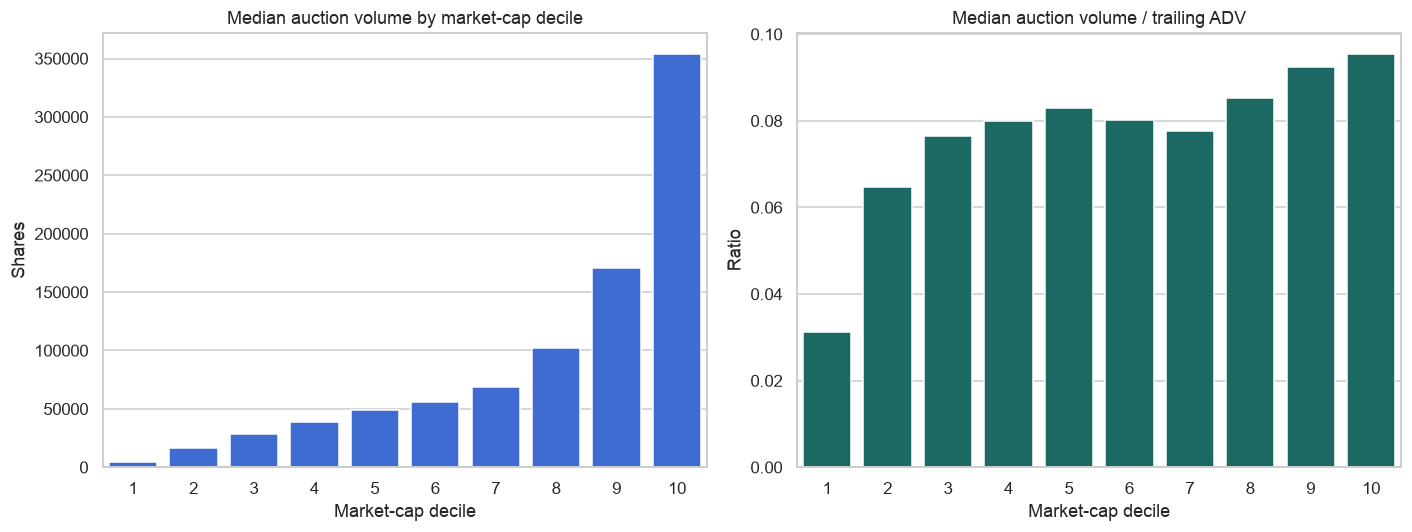

In [16]:
size_deciles = sql('\nWITH ranked AS (\n  SELECT *, ntile(10) OVER (PARTITION BY date ORDER BY market_cap_usd) AS size_decile\n  FROM eligible_targets WHERE market_cap_usd IS NOT NULL\n)\nSELECT size_decile, count(*) AS observations,\n       median(market_cap_usd) AS median_market_cap,\n       median(auction_volume) AS median_auction_volume,\n       avg(log1p_auction_volume) AS mean_log_volume,\n       median(auction_to_adv20) AS median_auction_to_adv20,\n       median(auction_share_daily_volume) AS median_auction_share\nFROM ranked GROUP BY 1 ORDER BY 1\n')
display(size_deciles)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=size_deciles, x='size_decile', y='median_auction_volume', color='#2563eb', ax=axes[0])
axes[0].set(title='Median auction volume by market-cap decile', xlabel='Market-cap decile', ylabel='Shares')
sns.barplot(data=size_deciles, x='size_decile', y='median_auction_to_adv20', color='#0f766e', ax=axes[1])
axes[1].set(title='Median auction volume / trailing ADV', xlabel='Market-cap decile', ylabel='Ratio')
fig.tight_layout()
plt.show()

## Persistence of the target

,pooled_lag1_correlation,pooled_lag5_correlation,lag1_pairs,lag5_pairs
0,0.8944,0.8806,3497252,3488662


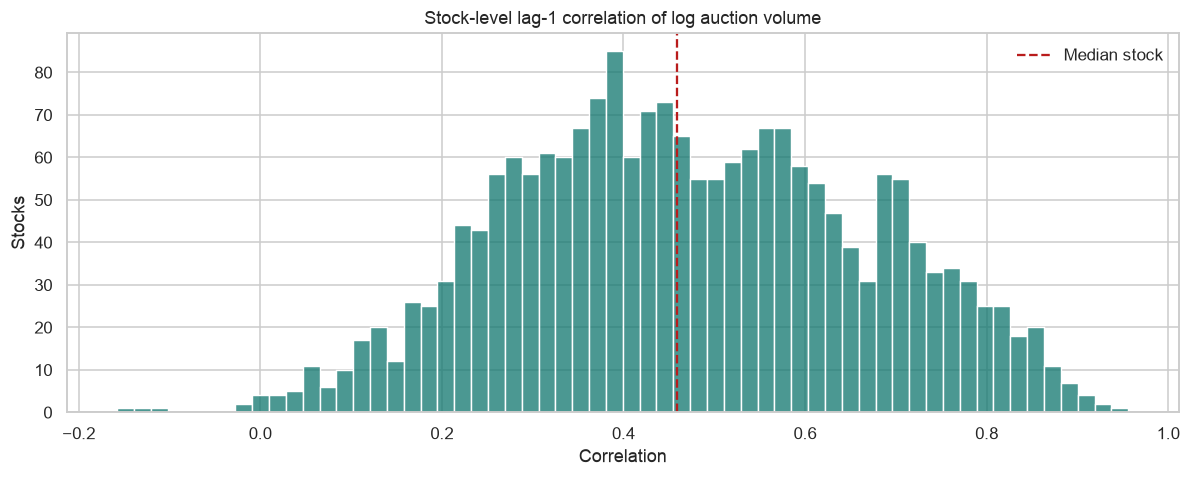

In [17]:
persistence = sql('\nWITH z AS (\n  SELECT date, permno, log1p_auction_volume,\n         lag(log1p_auction_volume, 1) OVER (PARTITION BY permno ORDER BY date) AS lag1,\n         lag(log1p_auction_volume, 5) OVER (PARTITION BY permno ORDER BY date) AS lag5\n  FROM eligible_targets\n)\nSELECT corr(log1p_auction_volume, lag1) AS pooled_lag1_correlation,\n       corr(log1p_auction_volume, lag5) AS pooled_lag5_correlation,\n       count(*) FILTER (WHERE lag1 IS NOT NULL) AS lag1_pairs,\n       count(*) FILTER (WHERE lag5 IS NOT NULL) AS lag5_pairs\nFROM z\n')
display(persistence)
stock_persistence = sql('\nWITH z AS (\n  SELECT date, permno, log1p_auction_volume,\n         lag(log1p_auction_volume, 1) OVER (PARTITION BY permno ORDER BY date) AS lag1\n  FROM eligible_targets\n), by_stock AS (\n  SELECT permno, count(lag1) AS pairs, corr(log1p_auction_volume, lag1) AS lag1_correlation\n  FROM z GROUP BY permno\n)\nSELECT * FROM by_stock WHERE pairs >= 100 AND lag1_correlation IS NOT NULL\n')
fig, ax = plt.subplots()
sns.histplot(stock_persistence['lag1_correlation'], bins=60, color='#0f766e', ax=ax)
ax.axvline(stock_persistence['lag1_correlation'].median(), color='#b91c1c', linestyle='--', label='Median stock')
ax.set(title='Stock-level lag-1 correlation of log auction volume', xlabel='Correlation', ylabel='Stocks')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Missing values and chronological imputation

| Field type | Treatment | Reason |
| --- | --- | --- |
| Missing auction label | Keep missing and exclude from supervised scoring | Zero shares would invent an outcome |
| Missing lag or rolling history | Retain missing until a model fit | Missingness can identify short history or absent records |
| Continuous model input | Historical median after any fitted transformation and clipping, plus a missing flag when seen during fitting | Preserve rows while making missingness observable |
| Binary input | Zero fill with a missing flag when required | Distinguish absent information from a recorded flag |
| Categorical input | Fit levels historically and encode unseen levels explicitly | Keep later observations compatible with the fitted model |
| Missing target reference | Use a fitting-sample auction median when reconstructing a model target | Supply a historical scale for cold starts |

The demonstration below creates lagged raw covariates before splitting by date. All preprocessing parameters are fitted on the earlier period. The model-specific rolling folds will refit those parameters separately. A full-sample median would allow later observations to influence earlier fits.

In [18]:
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor
lagged = sql(f"""
    WITH history AS (
        SELECT date, permno,
               lag(daily_volume) OVER w AS lag_volume,
               lag(market_cap_usd) OVER w AS lag_market_cap,
               lag(return_total) OVER w AS lag_return,
               lag(close) OVER w AS lag_price
        FROM read_parquet('{CRSP}', union_by_name=true)
        WINDOW w AS (PARTITION BY permno ORDER BY date)
    )
    SELECT * FROM history WHERE date BETWEEN DATE '2015-01-01' AND DATE '2023-12-31'
    ORDER BY date, permno
""")
features = ['lag_volume', 'lag_market_cap', 'lag_return', 'lag_price']
train = lagged[lagged.date < '2022-01-01'].sample(n=120000, random_state=42)
validation = lagged[lagged.date >= '2022-01-01'].sample(n=50000, random_state=42)
x_train, imputer = fit_preprocessor(train, features, [], [])
x_validation = apply_preprocessor(validation, imputer, features, [], [])
imputation = pd.DataFrame([
    {'feature': f, 'training_missing_rate': train[f].isna().mean(),
     'later_missing_rate': validation[f].isna().mean(), **imputer['continuous'][f]}
    for f in features
])
display(imputation)
assert train.date.max() < validation.date.min()
assert np.isfinite(x_train).all() and np.isfinite(x_validation).all()
print(f"Historical preprocessing produces {x_train.shape[1]} finite matrix columns.")
del lagged

,feature,training_missing_rate,later_missing_rate,log1p,lower,upper,median,scale,missing_indicator
0,lag_volume,0.0003,0.0001,True,0.0000,17.2957,13.3175,1.9996,True
1,lag_market_cap,0.0003,0.0001,True,17.2620,26.3036,21.7451,1.7946,True
2,lag_return,0.0006,0.0002,False,-0.1034,0.1199,0.0003,0.0261,True
3,lag_price,0.0062,0.0140,False,0.8757,684.6104,36.2900,80.1598,True


Historical preprocessing produces 8 finite matrix columns.


## Data decisions carried forward

Use 2015–2025 for labelled auction analysis and retain earlier CRSP rows for historical windows. Keep the supplied anomaly exclusion and observed-label rule explicit. Preserve missing predictors until fitting, and fit transformations inside each chronological training window.

The descriptive split above demonstrates preprocessing only. Model selection later uses 2022–2024 development folds and reports the previously inspected 2025 period separately. Each evaluation year is predicted by a model fitted on earlier dates.

Continue to [02 — Target variables](02_target_variables.ipynb).

In [19]:
assert int(panel_summary.eligible_rows.iloc[0]) == 3499401
print('Verified eligible label count and raw integrity checks.')
con.close()
work.cleanup()

Verified eligible label count and raw integrity checks.
